# Лабораторная работа №1. Linear Regression и Logistic Regression

- **Часть A** — линейная регрессия, Bike Sharing (`day.csv`), target `cnt`.
- **Часть B** — логистическая регрессия, Spaceship Titanic (`train.csv`), target `Transported`.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

DATA_DIR = Path("../data")
TEST_SIZE = 0.2
RANDOM_STATE = 42

## Общие инструменты

Собственный train/test split и метрики — используются в обеих частях.

In [2]:
def train_test_split_own(n_samples, test_size=0.2, random_state=42):
    # Перемешивает номера строк с фиксированным seed и режет на train и test.
    rng = np.random.default_rng(random_state)
    shuffled = rng.permutation(n_samples)

    n_test = int(round(n_samples * test_size))
    return shuffled[n_test:], shuffled[:n_test]

In [3]:
# Метрики регрессии

def mae(y_true, y_pred):
    # Средняя абсолютная ошибка, в единицах таргета.
    return float(np.mean(np.abs(y_true - y_pred)))


def rmse(y_true, y_pred):
    # Корень из среднего квадрата ошибки: сильнее реагирует на крупные промахи, чем MAE.
    return float(np.sqrt(np.mean((y_true - y_pred) ** 2)))


def r2(y_true, y_pred):
    # Доля разброса таргета, объяснённая моделью относительно предсказания средним.
    ss_res = np.sum((y_true - y_pred) ** 2)
    ss_tot = np.sum((y_true - np.mean(y_true)) ** 2)
    return float(1 - ss_res / ss_tot)

In [4]:
# Метрики классификации

def confusion_matrix(y_true, y_pred):
    tp = int(np.sum((y_pred == 1) & (y_true == 1)))  # сказали 1, и это 1
    fp = int(np.sum((y_pred == 1) & (y_true == 0)))  # сказали 1, а это 0
    fn = int(np.sum((y_pred == 0) & (y_true == 1)))  # сказали 0, а это 1
    tn = int(np.sum((y_pred == 0) & (y_true == 0)))  # сказали 0, и это 0
    return tp, fp, fn, tn


def accuracy(y_true, y_pred):
    # Доля правильных ответов среди всех.
    return float(np.mean(y_true == y_pred))


def precision(y_true, y_pred):
    # Из предсказанных единиц — какая доля действительно единицы.
    tp, fp, _, _ = confusion_matrix(y_true, y_pred)
    return tp / (tp + fp)


def recall(y_true, y_pred):
    # Из реальных единиц — какую долю модель нашла.
    tp, _, fn, _ = confusion_matrix(y_true, y_pred)
    return tp / (tp + fn)


def f1(y_true, y_pred):
    # Гармоническое среднее precision и recall.
    p, r = precision(y_true, y_pred), recall(y_true, y_pred)
    return 2 * p * r / (p + r)


def log_loss(y_true, y_proba):
    # BCE: учитывает не класс, а уверенность.
    y_proba = np.clip(y_proba, 1e-15, 1 - 1e-15)
    return float(-np.mean(y_true * np.log(y_proba) + (1 - y_true) * np.log(1 - y_proba)))

# Часть A. Linear Regression (Bike Sharing)

In [5]:
TARGET_A = "cnt"
LEARNING_RATE_A = 0.05
EPOCHS_A = 10000
PLOT_EPOCHS_A = 300

DROP_LEAKAGE = ["casual", "registered"]  # части таргета: cnt = casual + registered
DROP_SERVICE_A = ["instant", "dteday"]  # номер строки и сырая дата

NUMERIC_A = ["temp", "atemp", "hum", "windspeed"]  # стандартизуем
BINARY_A = ["yr", "holiday", "workingday"]  # уже 0/1
CATEGORICAL_A = ["season", "mnth", "weekday", "weathersit"]  # one-hot

## A1. Загрузка и краткое исследование датасета

In [6]:
df_a = pd.read_csv(DATA_DIR / "bike_sharing/day.csv")

print(f"размер {df_a.shape[0]}x{df_a.shape[1]} | пропусков {int(df_a.isna().sum().sum())} | "
      f"дубликатов {int(df_a.duplicated().sum())} | cnt {df_a[TARGET_A].min()}..{df_a[TARGET_A].max()}, "
      f"среднее {df_a[TARGET_A].mean():.0f}")
print(f"cnt == casual + registered: "
      f"{bool((df_a['casual'] + df_a['registered'] == df_a[TARGET_A]).all())}")

corr = (df_a[NUMERIC_A + BINARY_A + [TARGET_A]].corr()[TARGET_A]
        .drop(TARGET_A).sort_values(ascending=False))
print("корреляция с cnt:", ", ".join(f"{name} {value:.2f}" for name, value in corr.items()))

df_a.head()

размер 731x16 | пропусков 0 | дубликатов 0 | cnt 22..8714, среднее 4504
cnt == casual + registered: True
корреляция с cnt: atemp 0.63, temp 0.63, yr 0.57, workingday 0.06, holiday -0.07, hum -0.10, windspeed -0.23


,instant,dteday,season,yr,mnth,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,6,0,2,0.344167,0.363625,0.805833,0.160446,331,654,985
1,2,2011-01-02,1,0,1,0,0,0,2,0.363478,0.353739,0.696087,0.248539,131,670,801
2,3,2011-01-03,1,0,1,0,1,1,1,0.196364,0.189405,0.437273,0.248309,120,1229,1349
3,4,2011-01-04,1,0,1,0,2,1,1,0.200000,0.212122,0.590435,0.160296,108,1454,1562
4,5,2011-01-05,1,0,1,0,3,1,1,0.226957,0.229270,0.436957,0.186900,82,1518,1600


## A2. Формирование X и y

Убираем `casual` и `registered` (leakage: их сумма равна `cnt`),
`instant` (номер строки) и `dteday` (сырая дата — информация уже есть в `yr`, `mnth`, `weekday`, `holiday`).

In [7]:
X_df_a = df_a.drop(columns=DROP_LEAKAGE + DROP_SERVICE_A + [TARGET_A])
y_a = df_a[TARGET_A].to_numpy(dtype=float)

print(f"X {X_df_a.shape}, y {y_a.shape}")
print(f"убраны {', '.join(DROP_LEAKAGE)} (leakage), {', '.join(DROP_SERVICE_A)} (служебные)")

X (731, 11), y (731,)
убраны casual, registered (leakage), instant, dteday (служебные)


## A4. Train/test split

Split выполняется до препроцессинга: статистики для стандартизации и уровни
one-hot считаются только по train, иначе информация из test утечёт в обучение.

In [8]:
train_idx_a, test_idx_a = train_test_split_own(len(X_df_a), TEST_SIZE, RANDOM_STATE)

X_train_df_a, X_test_df_a = X_df_a.iloc[train_idx_a], X_df_a.iloc[test_idx_a]
y_train_a, y_test_a = y_a[train_idx_a], y_a[test_idx_a]

print(f"train {len(train_idx_a)}, test {len(test_idx_a)} (test_size={TEST_SIZE}, seed={RANDOM_STATE})")

train 585, test 146 (test_size=0.2, seed=42)


## A3. Очистка и preprocessing

Пропусков и дубликатов нет. Числовые признаки стандартизуются (среднее и std из train),
категориальные кодируются one-hot с отбрасыванием первого уровня,
бинарные остаются как есть.

In [9]:
class Preprocessor:

    def __init__(self, numeric, binary, categorical):
        self.numeric = list(numeric)
        self.binary = list(binary)
        self.categorical = list(categorical)

        self.levels_ = {}
        self.mean_ = None
        self.std_ = None

    def fit(self, df):
        # Вычисляет статистики по обучающей выборке.
        for col in self.categorical:
            levels = np.sort(df[col].unique())
            self.levels_[col] = levels[1:]  # первый уровень — точка отсчёта (dummy trap)

        values = df[self.numeric].to_numpy(dtype=float)
        self.mean_ = values.mean(axis=0)
        self.std_ = values.std(axis=0)
        return self

    def transform(self, df):
        # Применяет вычисленные на fit статистики. Возвращает матрицу признаков (N, D).
        numeric = (df[self.numeric].to_numpy(dtype=float) - self.mean_) / self.std_
        binary = df[self.binary].to_numpy(dtype=float)
        dummies = [
            (df[col].to_numpy()[:, None] == self.levels_[col][None, :]).astype(float)
            for col in self.categorical
        ]

        return np.hstack([numeric, binary] + dummies)

In [10]:
prep_a = Preprocessor(NUMERIC_A, BINARY_A, CATEGORICAL_A).fit(X_train_df_a)  # fit только на train

X_train_a = prep_a.transform(X_train_df_a)
X_test_a = prep_a.transform(X_test_df_a)

print(f"X_train {X_train_a.shape}, X_test {X_test_a.shape}")

X_train (585, 29), X_test (146, 29)


## A5–A8. Класс LinearRegression и обучение градиентным спуском

Модель `ŷ = X @ w + b`, loss — MSE, полнобатчевый градиентный спуск.
Методы `__init__`, `fit`, `predict`; история loss сохраняется в `history_`.

In [11]:
class LinearRegression:
    # Линейная регрессия ŷ = X @ w + b, обучение полнобатчевым градиентным спуском по MSE.

    def __init__(self, learning_rate=0.05, epochs=5000):
        self.learning_rate = learning_rate
        self.epochs = epochs

        self.w = None
        self.b = None
        self.history_ = []  # loss (MSE) по эпохам

    def fit(self, X, y):
        # Подбор весов градиентным спуском.
        n_samples, n_features = X.shape

        self.w = np.zeros(n_features)
        self.b = 0.0
        self.history_ = []

        for _ in range(self.epochs):
            y_pred = X @ self.w + self.b
            error = y_pred - y
            self.history_.append(float(np.mean(error ** 2)))

            dw = 2 / n_samples * (X.T @ error)  # градиент MSE по весам
            db = 2 * float(np.mean(error))  # градиент MSE по bias

            self.w -= self.learning_rate * dw  # шаг против градиента
            self.b -= self.learning_rate * db

        return self

    def predict(self, X):
        # Применение обученных параметров к новым данным.
        return X @ self.w + self.b

In [12]:
model_a = LinearRegression(learning_rate=LEARNING_RATE_A, epochs=EPOCHS_A).fit(X_train_a, y_train_a)

print(f"lr={LEARNING_RATE_A}, epochs={EPOCHS_A} | "
      f"MSE {model_a.history_[0]:.0f} -> {model_a.history_[-1]:.0f}")

lr=0.05, epochs=10000 | MSE 24005131 -> 583656


## A9. График loss по эпохам

Показаны первые эпохи — дальше кривая выходит на плато.

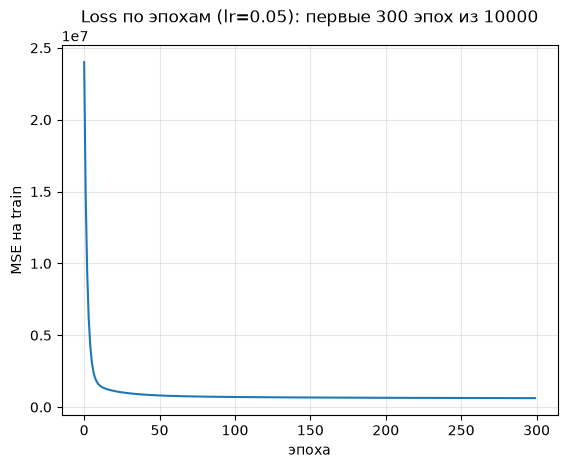

In [13]:
plt.plot(model_a.history_[:PLOT_EPOCHS_A])
plt.title(f"Loss по эпохам (lr={LEARNING_RATE_A}): первые {PLOT_EPOCHS_A} эпох из {EPOCHS_A}")
plt.xlabel("эпоха")
plt.ylabel("MSE на train")
plt.grid(True, alpha=0.3)
plt.show()

## A10. Метрики MAE, RMSE, R²

In [14]:
for name, X, y_true in [("train", X_train_a, y_train_a), ("test ", X_test_a, y_test_a)]:
    y_pred = model_a.predict(X)
    print(f"{name}: MAE {mae(y_true, y_pred):.0f}, RMSE {rmse(y_true, y_pred):.0f}, "
          f"R2 {r2(y_true, y_pred):.3f}")

train: MAE 555, RMSE 764, R2 0.849
test : MAE 562, RMSE 734, R2 0.836


In [15]:
# Сверка собственных метрик с sklearn.metrics (разрешено ТЗ только для проверки)
from sklearn import metrics as skm

y_pred_test_a = model_a.predict(X_test_a)
print(f"MAE  своя {mae(y_test_a, y_pred_test_a):.6f} | sklearn {skm.mean_absolute_error(y_test_a, y_pred_test_a):.6f}")
print(f"RMSE своя {rmse(y_test_a, y_pred_test_a):.6f} | sklearn {skm.root_mean_squared_error(y_test_a, y_pred_test_a):.6f}")
print(f"R2   своя {r2(y_test_a, y_pred_test_a):.6f} | sklearn {skm.r2_score(y_test_a, y_pred_test_a):.6f}")

MAE  своя 561.524501 | sklearn 561.524501
RMSE своя 733.529478 | sklearn 733.529478
R2   своя 0.836008 | sklearn 0.836008


## A11. Сравнение с baseline

Baseline всегда предсказывает среднее `cnt` по train.

In [16]:
baseline_pred_a = np.full_like(y_test_a, y_train_a.mean())
model_pred_a = model_a.predict(X_test_a)

print(f"baseline (всегда {y_train_a.mean():.0f}): MAE {mae(y_test_a, baseline_pred_a):.0f}, "
      f"RMSE {rmse(y_test_a, baseline_pred_a):.0f}, R2 {r2(y_test_a, baseline_pred_a):.3f}")
print(f"модель:              MAE {mae(y_test_a, model_pred_a):.0f}, "
      f"RMSE {rmse(y_test_a, model_pred_a):.0f}, R2 {r2(y_test_a, model_pred_a):.3f}")
print(f"модель точнее baseline в {mae(y_test_a, baseline_pred_a) / mae(y_test_a, model_pred_a):.1f} раза по MAE")

baseline (всегда 4488): MAE 1502, RMSE 1813, R2 -0.002
модель:              MAE 562, RMSE 734, R2 0.836
модель точнее baseline в 2.7 раза по MAE


# Часть B. Logistic Regression (Spaceship Titanic)

Используется только размеченный `train.csv`, competition `test.csv` не используется.

In [17]:
TARGET_B = "Transported"
LEARNING_RATE_B = 0.1
EPOCHS_B = 2000

DROP_SERVICE_B = ["PassengerId", "Name", "Cabin"]  # ID, имя и исходная каюта (разбирается на Deck и Side)

SPEND = ["RoomService", "FoodCourt", "ShoppingMall", "Spa", "VRDeck"]  # скошены, логарифмируем

NUMERIC_B = ["Age"] + SPEND  # стандартизуем
BINARY_B = ["CryoSleep", "VIP"]  # True/False -> 1/0
CATEGORICAL_B = ["HomePlanet", "Destination", "Deck", "Side"]  # one-hot


def split_cabin(df):
    parts = df["Cabin"].str.split("/", expand=True)  # формат каюты: палуба/номер/сторона
    return parts[0], parts[1], parts[2]

## B1. Загрузка и краткое исследование датасета

In [18]:
df_b = pd.read_csv(DATA_DIR / "spaceship_titanic/train.csv")

deck, _, side = split_cabin(df_b)
rows_with_na = int(df_b.isna().any(axis=1).sum())
spend_zero = (df_b[SPEND] == 0).mean()

print(f"размер {df_b.shape[0]}x{df_b.shape[1]} | строк хотя бы с одним пропуском {rows_with_na} "
      f"({100 * rows_with_na / len(df_b):.0f}%), по столбцам 2-3%")

balance = df_b[TARGET_B].value_counts(normalize=True)
print(f"таргет {TARGET_B}: True {balance[True]:.3f}, False {balance[False]:.3f} — классы сбалансированы")

print(f"категории: HomePlanet {df_b['HomePlanet'].nunique()}, Destination {df_b['Destination'].nunique()}, "
      f"палуб {deck.nunique()}, сторон {side.nunique()}")
print(f"траты: медиана {df_b[SPEND].median().max():.0f}, максимум {df_b[SPEND].max().max():.0f}, "
      f"нулевых {100 * spend_zero.min():.0f}-{100 * spend_zero.max():.0f}%")

cryo = df_b.groupby("CryoSleep")[TARGET_B].mean()
no_spend = df_b.assign(zero=df_b[SPEND].fillna(0).sum(axis=1) == 0).groupby("zero")[TARGET_B].mean()
print(f"доля Transported: CryoSleep True {cryo[True]:.2f} / False {cryo[False]:.2f} | "
      f"нулевые траты {no_spend[True]:.2f} / {no_spend[False]:.2f}")

df_b.head()

размер 8693x14 | строк хотя бы с одним пропуском 2087 (24%), по столбцам 2-3%
таргет Transported: True 0.504, False 0.496 — классы сбалансированы
категории: HomePlanet 3, Destination 3, палуб 8, сторон 2
траты: медиана 0, максимум 29813, нулевых 61-64%
доля Transported: CryoSleep True 0.82 / False 0.33 | нулевые траты 0.79 / 0.30


,PassengerId,HomePlanet,CryoSleep,Cabin,Destination,Age,VIP,RoomService,FoodCourt,ShoppingMall,Spa,VRDeck,Name,Transported
0,0001_01,Europa,False,B/0/P,TRAPPIST-1e,39.0,False,0.0,0.0,0.0,0.0,0.0,Maham Ofracculy,False
1,0002_01,Earth,False,F/0/S,TRAPPIST-1e,24.0,False,109.0,9.0,25.0,549.0,44.0,Juanna Vines,True
2,0003_01,Europa,False,A/0/S,TRAPPIST-1e,58.0,True,43.0,3576.0,0.0,6715.0,49.0,Altark Susent,False
3,0003_02,Europa,False,A/0/S,TRAPPIST-1e,33.0,False,0.0,1283.0,371.0,3329.0,193.0,Solam Susent,False
4,0004_01,Earth,False,F/1/S,TRAPPIST-1e,16.0,False,303.0,70.0,151.0,565.0,2.0,Willy Santantines,True


## B2. Формирование X и y

`Cabin` разбирается на палубу `Deck` и сторону `Side` (номер каюты не берём),
`PassengerId`, `Name` и исходный `Cabin` убираются.

In [19]:
X_df_b = df_b.drop(columns=DROP_SERVICE_B + [TARGET_B]).assign(Deck=deck, Side=side)
y_b = df_b[TARGET_B].to_numpy(dtype=float)  # bool -> 1.0 / 0.0

print(f"X {X_df_b.shape}, y {y_b.shape}")
print(f"Cabin разобран на Deck и Side, убраны {', '.join(DROP_SERVICE_B)}")

X (8693, 12), y (8693,)
Cabin разобран на Deck и Side, убраны PassengerId, Name, Cabin


## B5. Train/test split

Как и в части A, split делается **до** препроцессинга (пункты 3–4), чтобы моды, медианы
и статистики стандартизации считались только по train.

In [20]:
train_idx_b, test_idx_b = train_test_split_own(len(X_df_b), TEST_SIZE, RANDOM_STATE)

X_train_df_b, X_test_df_b = X_df_b.iloc[train_idx_b], X_df_b.iloc[test_idx_b]
y_train_b, y_test_b = y_b[train_idx_b], y_b[test_idx_b]

print(f"train {len(train_idx_b)}, test {len(test_idx_b)} (test_size={TEST_SIZE}, seed={RANDOM_STATE})")
# при дисбалансе классов понадобилась бы стратификация, здесь классы и так 50/50
print(f"доля класса 1: train {y_train_b.mean():.3f}, test {y_test_b.mean():.3f}")

train 6954, test 1739 (test_size=0.2, seed=42)
доля класса 1: train 0.506, test 0.494


## B3–B4. Пропуски, категориальные признаки и preprocessing

- категории и бинарные — модой train; `Age` — медианой train;
- траты — 0 у пассажиров в криосне, иначе медианой бодрствующих из train;
- `log1p` для трат (сильно скошены), стандартизация числовых;
- one-hot для категорий с отбрасыванием первого уровня.

In [21]:
class PreprocessorB:
    # Импутация пропусков, log1p трат, one-hot и стандартизация.

    def __init__(self, numeric, binary, categorical, spend):
        self.numeric = list(numeric)
        self.binary = list(binary)
        self.categorical = list(categorical)
        self.spend = list(spend)

        self.modes_ = {}  # моды бинарных и категориальных признаков
        self.medians_ = {}  # медианы числовых признаков
        self.levels_ = {}
        self.mean_ = None
        self.std_ = None

    def fit(self, df):
        for col in self.binary + self.categorical:
            self.modes_[col] = df[col].mode()[0]

        # Медиана трат считается только по бодрствующим: у пассажиров в криосне траты
        # всегда нулевые, и их 63% — медиана по всем дала бы 0 и обнулила признак
        awake = df[df["CryoSleep"] == False]
        for col in self.numeric:
            self.medians_[col] = (awake[col] if col in self.spend else df[col]).median()

        filled = self._impute(df)

        for col in self.categorical:
            levels = np.sort(filled[col].unique())
            self.levels_[col] = levels[1:]

        values = self._numeric_matrix(filled)
        self.mean_ = values.mean(axis=0)
        self.std_ = values.std(axis=0)
        return self

    def _impute(self, df):
        out = df.copy()

        for col in self.binary + self.categorical:
            out[col] = out[col].fillna(self.modes_[col])

        # Пассажир в криосне физически не может ничего потратить, пропуск означает 0;
        # для бодрствующего подставляем медиану бодрствующих из train
        in_cryo = out["CryoSleep"] == True
        for col in self.spend:
            fill = pd.Series(np.where(in_cryo, 0.0, self.medians_[col]), index=out.index)
            out[col] = out[col].fillna(fill)

        out["Age"] = out["Age"].fillna(self.medians_["Age"])
        return out

    def _numeric_matrix(self, filled):
        # Числовые столбцы в матрицу, траты в логарифмическую шкалу.
        values = filled[self.numeric].to_numpy(dtype=float)
        spend_idx = [self.numeric.index(col) for col in self.spend]
        values[:, spend_idx] = np.log1p(values[:, spend_idx])
        return values

    def transform(self, df):
        filled = self._impute(df)

        numeric = (self._numeric_matrix(filled) - self.mean_) / self.std_
        binary = filled[self.binary].to_numpy(dtype=float)  # True/False -> 1.0/0.0
        dummies = [
            (filled[col].to_numpy()[:, None] == self.levels_[col][None, :]).astype(float)
            for col in self.categorical
        ]

        return np.hstack([numeric, binary] + dummies)

In [22]:
prep_b = PreprocessorB(NUMERIC_B, BINARY_B, CATEGORICAL_B, SPEND).fit(X_train_df_b)  # fit только на train

X_train_b = prep_b.transform(X_train_df_b)
X_test_b = prep_b.transform(X_test_df_b)

print(f"медианы трат (бодрствующие): {', '.join(f'{c} {prep_b.medians_[c]:.0f}' for c in SPEND)}")
print(f"log1p для {len(SPEND)} столбцов трат, one-hot для {', '.join(CATEGORICAL_B)}")
print(f"X_train {X_train_b.shape}, X_test {X_test_b.shape}, "
      f"пропусков {int(np.isnan(X_train_b).sum() + np.isnan(X_test_b).sum())}")

медианы трат (бодрствующие): RoomService 3, FoodCourt 5, ShoppingMall 1, Spa 8, VRDeck 5
log1p для 5 столбцов трат, one-hot для HomePlanet, Destination, Deck, Side
X_train (6954, 20), X_test (1739, 20), пропусков 0


## B6–B10. Класс LogisticRegression, градиентный спуск по BCE

Модель `p = sigmoid(X @ w + b)`, loss — BCE (LogLoss).
Методы `__init__`, `fit`, `predict_proba`, `predict`; история loss в `history_`.

In [23]:
class LogisticRegression:
    # Логистическая регрессия: p = sigmoid(X @ w + b), обучение градиентным спуском по BCE.

    def __init__(self, learning_rate=0.1, epochs=2000, threshold=0.5):
        self.learning_rate = learning_rate
        self.epochs = epochs
        self.threshold = threshold  # граница, по которой вероятность превращается в класс

        self.w = None
        self.b = None
        self.history_ = []  # loss (BCE) по эпохам

    @staticmethod
    def _sigmoid(z):
        # Сжимает любое число в диапазон (0, 1): большие z -> ближе к 1, малые -> ближе к 0.
        return 1 / (1 + np.exp(-z))

    def fit(self, X, y):
        # Подбор весов градиентным спуском по BCE.
        n_samples, n_features = X.shape

        self.w = np.zeros(n_features)
        self.b = 0.0
        self.history_ = []

        for _ in range(self.epochs):
            p = self.predict_proba(X)
            error = p - y

            self.history_.append(log_loss(y, p))  # loss = BCE

            dw = (X.T @ error) / n_samples  # градиент BCE по весам
            db = float(np.mean(error))  # градиент BCE по bias

            self.w -= self.learning_rate * dw  # шаг против градиента
            self.b -= self.learning_rate * db

        return self

    def predict_proba(self, X):
        # Вероятность класса 1 для каждого объекта.
        z = X @ self.w + self.b  # линейная часть (score), как в линейной регрессии
        return self._sigmoid(z)

    def predict(self, X):
        # Жёсткий ответ: вероятность выше порога -> класс 1, иначе 0.
        return (self.predict_proba(X) >= self.threshold).astype(float)

In [24]:
model_b = LogisticRegression(learning_rate=LEARNING_RATE_B, epochs=EPOCHS_B).fit(X_train_b, y_train_b)

# старт 0.6931 = ln(2): при нулевых весах модель всем даёт p = 0.5
print(f"lr={LEARNING_RATE_B}, epochs={EPOCHS_B} | "
      f"BCE {model_b.history_[0]:.4f} -> {model_b.history_[-1]:.4f}")

lr=0.1, epochs=2000 | BCE 0.6931 -> 0.4768


## B11. График loss по эпохам

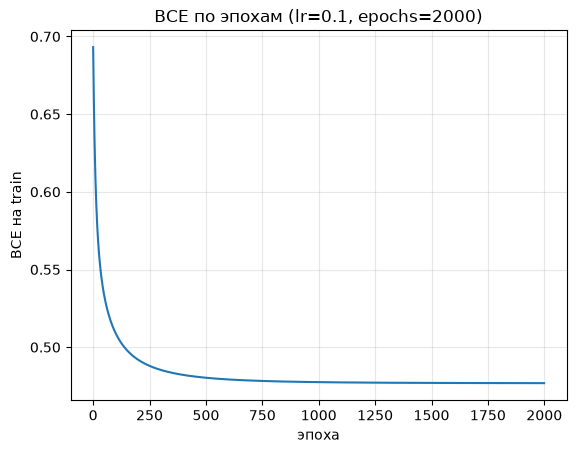

In [25]:
plt.plot(model_b.history_)
plt.title(f"BCE по эпохам (lr={LEARNING_RATE_B}, epochs={EPOCHS_B})")
plt.xlabel("эпоха")
plt.ylabel("BCE на train")
plt.grid(True, alpha=0.3)
plt.show()

## B12. Метрики Accuracy, Precision, Recall, F1, LogLoss

In [26]:
for name, X, y_true in [("train", X_train_b, y_train_b), ("test ", X_test_b, y_test_b)]:
    y_pred, y_proba = model_b.predict(X), model_b.predict_proba(X)
    print(f"{name}: Accuracy {accuracy(y_true, y_pred):.3f}, Precision {precision(y_true, y_pred):.3f}, "
          f"Recall {recall(y_true, y_pred):.3f}, F1 {f1(y_true, y_pred):.3f}, "
          f"LogLoss {log_loss(y_true, y_proba):.4f}")

train: Accuracy 0.780, Precision 0.774, Recall 0.799, F1 0.786, LogLoss 0.4768
test : Accuracy 0.783, Precision 0.766, Recall 0.808, F1 0.786, LogLoss 0.4788


In [27]:
# Сверка собственных метрик с sklearn.metrics (разрешено ТЗ только для проверки)
y_pred_test_b, y_proba_test_b = model_b.predict(X_test_b), model_b.predict_proba(X_test_b)

checks = [
    ("Accuracy ", accuracy(y_test_b, y_pred_test_b), skm.accuracy_score(y_test_b, y_pred_test_b)),
    ("Precision", precision(y_test_b, y_pred_test_b), skm.precision_score(y_test_b, y_pred_test_b)),
    ("Recall   ", recall(y_test_b, y_pred_test_b), skm.recall_score(y_test_b, y_pred_test_b)),
    ("F1       ", f1(y_test_b, y_pred_test_b), skm.f1_score(y_test_b, y_pred_test_b)),
    ("LogLoss  ", log_loss(y_test_b, y_proba_test_b), skm.log_loss(y_test_b, y_proba_test_b)),
]
for name, own, ref in checks:
    print(f"{name} своя {own:.6f} | sklearn {ref:.6f}")

Accuracy  своя 0.783209 | sklearn 0.783209
Precision своя 0.766004 | sklearn 0.766004
Recall    своя 0.807916 | sklearn 0.807916
F1        своя 0.786402 | sklearn 0.786402
LogLoss   своя 0.478803 | sklearn 0.478803


## B13. Confusion matrix (test)

In [28]:
tp, fp, fn, tn = confusion_matrix(y_test_b, model_b.predict(X_test_b))

print("                предсказали 1   предсказали 0")
print(f"реально 1       TP = {tp:<11} FN = {fn}")
print(f"реально 0       FP = {fp:<11} TN = {tn}")

                предсказали 1   предсказали 0
реально 1       TP = 694         FN = 165
реально 0       FP = 212         TN = 668


## B14. Сравнение с majority baseline

Baseline всегда отвечает классом, которого в train больше. Для LogLoss ему нужна
вероятность — берём долю класса 1 в train.

In [29]:
major_class = float(y_train_b.mean() >= 0.5)  # класс, которого в train больше
base_pred_b = np.full_like(y_test_b, major_class)  # этот класс каждому объекту test
base_proba_b = np.full_like(y_test_b, y_train_b.mean())  # уверенность = доля класса 1, нужна для LogLoss

model_pred_b, model_proba_b = model_b.predict(X_test_b), model_b.predict_proba(X_test_b)

print(f"baseline (всегда класс {major_class:.0f}, p={y_train_b.mean():.3f}): "
      f"Accuracy {accuracy(y_test_b, base_pred_b):.3f}, Precision {precision(y_test_b, base_pred_b):.3f}, "
      f"Recall {recall(y_test_b, base_pred_b):.3f}, F1 {f1(y_test_b, base_pred_b):.3f}, "
      f"LogLoss {log_loss(y_test_b, base_proba_b):.4f}")
print(f"наша модель: Accuracy {accuracy(y_test_b, model_pred_b):.3f}, "
      f"Precision {precision(y_test_b, model_pred_b):.3f}, Recall {recall(y_test_b, model_pred_b):.3f}, "
      f"F1 {f1(y_test_b, model_pred_b):.3f}, LogLoss {log_loss(y_test_b, model_proba_b):.4f}")

baseline (всегда класс 1, p=0.506): Accuracy 0.494, Precision 0.494, Recall 1.000, F1 0.661, LogLoss 0.6934
наша модель: Accuracy 0.783, Precision 0.766, Recall 0.808, F1 0.786, LogLoss 0.4788
